# Robustness of quantized models: FP32 vs INT8 vs INT4

This notebook takes the **same three models** you already built in the accuracy study -- the 32-bit float model, the real int8 quantized model, and the 4-bit weight-only model -- and puts them through the robustness protocol of the **RobustMQ** benchmark (Xiao et al., *RobustMQ: Benchmarking Robustness of Quantized Models*, arXiv:2308.02350).

RobustMQ classifies perturbations into three families, and we use the same three:

1. **Adversarial attacks** -- white-box FGSM and PGD at three perturbation budgets (small / middle / large).
2. **Natural corruptions** -- noise, blur, weather and digital corruptions at two severity levels each.
3. **Systematic noises** -- image resize interpolation modes, which differ between deployment libraries.

The metrics are also taken from the paper:

| Metric | Meaning |
|---|---|
| `ACC` | clean accuracy |
| `AR` | accuracy under a specific attack (higher = more robust) |
| `AAI` | `(ACC - AR) / ACC`, the relative drop (lower = more robust) |
| `WCAR` | worst-case adversarial robustness: accuracy when *no* attack in the set succeeds |
| `mNR` | mean natural robustness: mean accuracy over all corruptions |
| `NCI` | `(ACC - mNR) / ACC`, the relative corruption drop |
| `SR` | standard deviation of accuracy over the systematic-noise settings (lower = more stable) |

**What RobustMQ found, so you know what to look for:** quantized models showed *higher* adversarial robustness than their float counterpart, but *lower* natural and systematic robustness; and within one quantization method, **lower bit-width meant better adversarial robustness but worse natural robustness**. That gives us a concrete prediction for our three models:

- adversarial robustness: **INT4 > INT8 > FP32**
- natural robustness: **FP32 > INT8 > INT4**

## Honest differences from the paper (say these out loud)

- RobustMQ used **ImageNet**, 4 architectures and 4 bit-widths (2/4/6/8) with **QAT** methods (DoReFa, PACT, LSQ). We use **CIFAR-10**, one small CNN, and 8/4 bits with **post-training quantization** (PTQ). So this is a *miniature of the protocol*, not a reproduction.
- Their adversarial-robustness gain is largely a **regularization effect of QAT** -- training adapted to the rounding. Our PTQ models never adapted, so the gap may be much smaller, or absent. Finding that out is the point.
- **Attacks need gradients**, and PyTorch's int8 kernels are not differentiable. So the INT8 attack is generated on a *differentiable twin*: the same architecture with the *dequantized int8 weights* computed in float (a BPDA-style approximation). INT4 already computes in float, so it is attacked exactly. This makes the INT8 numbers slightly *optimistic*.
- Only **1,000 test images** are used, so differences below roughly 3 percentage points are inside the noise.


In [1]:
import copy
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0 if os.name == "nt" else 2

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

# images are kept in pixel space [0, 1] so that perturbations can be clipped correctly;
# every model receives NORMALIZE(x) instead
NORMALIZE = transforms.Normalize(CIFAR_MEAN, CIFAR_STD)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])

train_set = datasets.CIFAR10(root="./cifar10", train=True, download=True, transform=train_transform)
calib_set = datasets.CIFAR10(root="./cifar10", train=True, download=True, transform=eval_transform)
pixel_test_set = datasets.CIFAR10(root="./cifar10", train=False, download=True, transform=transforms.ToTensor())

BATCH_SIZE = 128
TRAIN_N = 50000 if device.type == "cuda" else 12000
EPOCHS = 8 if device.type == "cuda" else 6
ROBUST_N = 1000          # images used for the whole robustness study
ROBUST_BATCH = 100

train_loader = DataLoader(Subset(train_set, range(TRAIN_N)), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
calib_loader = DataLoader(Subset(calib_set, range(512)), batch_size=64, shuffle=False)
robust_loader = DataLoader(Subset(pixel_test_set, range(ROBUST_N)), batch_size=ROBUST_BATCH, shuffle=False)

print(f"device        : {device}")
print(f"training on   : {TRAIN_N} images, {EPOCHS} epochs")
print(f"robustness on : {ROBUST_N} test images")


100%|██████████| 170M/170M [28:27<00:00, 99.8kB/s]


device        : cpu
training on   : 12000 images, 6 epochs
robustness on : 1000 test images


In [2]:
from torch.ao.quantization import QuantStub, DeQuantStub


class SimpleCNN(nn.Module):
    """The same small quantization-friendly CNN as in the accuracy study."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.quant = QuantStub()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.relu3 = nn.ReLU()
        self.conv4 = nn.Conv2d(128, 128, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.relu4 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.relu5 = nn.ReLU()
        self.fc2 = nn.Linear(256, num_classes)
        self.dequant = DeQuantStub()

    def forward(self, x):
        x = self.quant(x)
        x = self.relu1(self.bn1(self.conv1(x)))
        x = self.pool1(self.relu2(self.bn2(self.conv2(x))))
        x = self.relu3(self.bn3(self.conv3(x)))
        x = self.pool2(self.relu4(self.bn4(self.conv4(x))))
        x = torch.flatten(x, 1)
        x = self.relu5(self.fc1(x))
        x = self.fc2(x)
        return self.dequant(x)


def train(model, loader, epochs, device):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    for epoch in range(epochs):
        running_loss, correct, seen = 0.0, 0, 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            seen += labels.size(0)
        scheduler.step()
        print(f"epoch {epoch + 1:2d}/{epochs}   loss {running_loss / seen:.4f}   train accuracy {100 * correct / seen:5.2f}%")
    model.eval()
    return model


model_fp32 = SimpleCNN().to(device)
print(f"parameters: {sum(p.numel() for p in model_fp32.parameters()):,}")
model_fp32 = train(model_fp32, train_loader, EPOCHS, device)
print("training done")


parameters: 2,341,514
epoch  1/6   loss 1.9133   train accuracy 32.35%
epoch  2/6   loss 1.5071   train accuracy 44.23%
epoch  3/6   loss 1.3223   train accuracy 51.06%
epoch  4/6   loss 1.2099   train accuracy 55.88%
epoch  5/6   loss 1.0871   train accuracy 61.18%
epoch  6/6   loss 1.0163   train accuracy 63.54%
training done


In [3]:
from torch.ao.quantization import convert, fuse_modules, get_default_qconfig, prepare

FUSE_LIST = [["conv1", "bn1", "relu1"], ["conv2", "bn2", "relu2"],
             ["conv3", "bn3", "relu3"], ["conv4", "bn4", "relu4"], ["fc1", "relu5"]]
WEIGHT_LAYERS = ["conv1", "conv2", "conv3", "conv4", "fc1", "fc2"]

# ---------------- INT8: real post-training static quantization ----------------
try:
    torch.backends.quantized.engine = "x86"
    qconfig = get_default_qconfig("x86")
except Exception:
    torch.backends.quantized.engine = "fbgemm"
    qconfig = get_default_qconfig("fbgemm")

fused_for_int8 = fuse_modules(copy.deepcopy(model_fp32).cpu().eval(), FUSE_LIST)
fused_for_int8.qconfig = qconfig
prepared = prepare(fused_for_int8, inplace=False)
prepared.eval()
with torch.no_grad():
    for images, _ in calib_loader:
        prepared(images)
model_int8 = convert(prepared, inplace=False)
print(f"INT8 model: conv1 is {type(model_int8.conv1).__name__}, "
      f"weight dtype {model_int8.conv1.weight().dtype}, "
      f"{torch.unique(model_int8.conv1.weight().int_repr()).numel()} of 256 levels used")

# ---------------- INT4: real 4-bit weight-only, packed two per byte ----------------
def int4_codes_and_scales(weight):
    flat = weight.reshape(weight.shape[0], -1)
    scale = (flat.abs().amax(dim=1, keepdim=True) / 7.0).clamp_min(1e-12)
    codes = torch.clamp(torch.round(flat / scale), -8, 7).to(torch.int16)
    return codes, scale


def pack_int4(codes):
    if codes.shape[1] % 2 == 1:
        codes = torch.nn.functional.pad(codes, (0, 1))
    unsigned = (codes + 8).to(torch.int16)
    return (unsigned[:, 0::2] | (unsigned[:, 1::2] << 4)).to(torch.uint8)


model_int4 = fuse_modules(copy.deepcopy(model_fp32).cpu().eval(), FUSE_LIST)
packed_state = {}
for name, module in model_int4.named_modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        codes, scale = int4_codes_and_scales(module.weight.data)
        module.weight.data = (codes.to(scale.dtype) * scale).reshape(module.weight.shape)
        packed_state[name + ".weight_packed"] = pack_int4(codes)
        packed_state[name + ".scales"] = scale.to(torch.float16)

torch.save(packed_state, "int4_robustness.pt")
size_int4 = os.path.getsize("int4_robustness.pt") / 1e6
print(f"INT4 model: conv1 weight packed into "
      f"{packed_state['conv1.0.weight_packed'].numel()} bytes for "
      f"{next(m for m in model_int4.conv1.modules() if isinstance(m, nn.Conv2d)).weight.numel()} weights, "
      f"file {size_int4:.2f} MB")


/tmp/ipykernel_1224/4158823005.py:17: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = prepare(fused_for_int8, inplace=False)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of 

INT8 model: conv1 is ConvReLU2d, weight dtype torch.qint8, 241 of 256 levels used
INT4 model: conv1 weight packed into 448 bytes for 864 weights, file 1.18 MB


In [4]:
# ---------------- The models we will attack ----------------
# PyTorch int8 kernels are not differentiable, so an attack on the int8 model cannot
# backpropagate through it. The standard workaround (BPDA style) is to attack a
# differentiable twin: the same fused architecture, running in float, holding the
# *dequantized* int8 weights. INT4 already runs in float, so it is attacked exactly.
int8_twin = copy.deepcopy(model_int4).cpu().eval()          # fused float architecture
for name in WEIGHT_LAYERS:
    quantized_weight = getattr(model_int8, name).weight()
    dequantized = quantized_weight.dequantize() if quantized_weight.dtype == torch.qint8 else quantized_weight.float()
    layer = getattr(int8_twin, name)
    inner = layer[0] if isinstance(layer, nn.Sequential) else layer
    inner.weight.data = dequantized.reshape(inner.weight.shape).clone()

int8_twin = int8_twin.to(device).eval()
model_fp32 = model_fp32.to(device).eval()
model_int4 = model_int4.to(device).eval()

# check the twin really reproduces the quantized model's decisions
with torch.no_grad():
    sample = torch.stack([pixel_test_set[i][0] for i in range(500)]).to(device)
    twin_pred = int8_twin(NORMALIZE(sample)).argmax(1).cpu()
    int8_pred = model_int8(NORMALIZE(sample).cpu()).argmax(1).cpu()
print(f"twin vs real int8 model: {100 * (twin_pred == int8_pred).float().mean().item():.2f}% identical predictions on 500 images")
print("(100% would mean the twin is exact; anything close means the attack surrogate is faithful)")


twin vs real int8 model: 97.00% identical predictions on 500 images
(100% would mean the twin is exact; anything close means the attack surrogate is faithful)


In [5]:
# ---------------- Adversarial attacks (white-box, L-inf, pixel space) ----------------
EPS_LIST = [("1/255", 1 / 255), ("2/255", 2 / 255), ("4/255", 4 / 255)]
PGD_STEPS = 10


def attack(surrogate, images, labels, eps, steps):
    """FGSM when steps == 1, PGD when steps > 1. Everything in pixel space [0, 1]."""
    surrogate.eval()
    if steps == 1:
        delta = torch.zeros_like(images)
        alpha = eps
    else:
        delta = torch.empty_like(images).uniform_(-eps, eps)
        alpha = eps / 4
    for _ in range(steps):
        delta = delta.detach().requires_grad_(True)
        loss = F.cross_entropy(surrogate(NORMALIZE((images + delta).clamp(0, 1))), labels)
        grad = torch.autograd.grad(loss, delta)[0]
        delta = (delta.detach() + alpha * grad.sign()).clamp(-eps, eps)
    return (images + delta).clamp(0, 1).detach()


# ---------------- Natural corruptions (two severity levels each) ----------------
def gaussian_noise(x, level):
    sigma = 0.05 if level == 1 else 0.15
    return (x + sigma * torch.randn_like(x)).clamp(0, 1)


def shot_noise(x, level):
    scale = 0.02 if level == 1 else 0.06
    return (torch.poisson(x / scale) * scale).clamp(0, 1)


def impulse_noise(x, level):
    fraction = 0.02 if level == 1 else 0.08
    mask = torch.rand_like(x)
    out = x.clone()
    out[mask < fraction / 2] = 0.0
    out[mask > 1 - fraction / 2] = 1.0
    return out


def _blur(x, size):
    channels = x.shape[1]
    kernel = torch.ones(channels, 1, size, size, device=x.device) / (size * size)
    pad = size // 2
    return F.conv2d(F.pad(x, (pad, pad, pad, pad), mode="reflect"), kernel, groups=channels)


def defocus_blur(x, level):
    return _blur(x, 3 if level == 1 else 5)


def motion_blur(x, level):
    size = 5 if level == 1 else 9
    channels = x.shape[1]
    kernel = torch.zeros(channels, 1, size, size, device=x.device)
    kernel[:, :, size // 2, :] = 1.0 / size
    pad = size // 2
    return F.conv2d(F.pad(x, (pad, pad, pad, pad), mode="reflect"), kernel, groups=channels)


def zoom_blur(x, level):
    factors = [1.0, 1.05, 1.1] if level == 1 else [1.0, 1.1, 1.2, 1.3]
    height, width = x.shape[-2:]
    total = torch.zeros_like(x)
    for factor in factors:
        crop = int(height / factor)
        top = (height - crop) // 2
        if crop == height:
            total += x
        else:
            zoomed = F.interpolate(x[:, :, top:top + crop, top:top + crop], size=(height, width),
                                   mode="bilinear", align_corners=False)
            total += zoomed
    return (total / len(factors)).clamp(0, 1)


def brightness(x, level):
    return (x + (0.1 if level == 1 else 0.3)).clamp(0, 1)


def contrast(x, level):
    factor = 0.75 if level == 1 else 0.5
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - mean) * factor + mean).clamp(0, 1)


def pixelate(x, level):
    height, width = x.shape[-2:]
    factor = 2 if level == 1 else 4
    small = F.interpolate(x, size=(height // factor, width // factor), mode="nearest")
    return F.interpolate(small, size=(height, width), mode="nearest")


def fog(x, level):
    strength = 0.2 if level == 1 else 0.4
    return ((1 - strength) * x + strength * 0.5).clamp(0, 1)


CORRUPTIONS = {
    "gaussian noise": gaussian_noise,
    "shot noise": shot_noise,
    "impulse noise": impulse_noise,
    "defocus blur": defocus_blur,
    "motion blur": motion_blur,
    "zoom blur": zoom_blur,
    "brightness": brightness,
    "contrast": contrast,
    "pixelate": pixelate,
    "fog": fog,
}

# ---------------- Systematic noises: resize interpolation modes ----------------
RESIZE_MODES = ["nearest", "bilinear", "bicubic", "area"]


def resize_input(x, mode):
    height, width = x.shape[-2:]
    small = F.interpolate(x, size=(height // 2, width // 2), mode=mode)
    return F.interpolate(small, size=(height, width), mode=mode)


def predict(model, dev, pixel_batch):
    model.eval()
    with torch.no_grad():
        return model(NORMALIZE(pixel_batch).to(dev)).argmax(1).cpu()


print(f"{len(CORRUPTIONS)} corruptions x 2 levels, {len(RESIZE_MODES)} resize modes, "
      f"{2 * len(EPS_LIST)} attack settings")


10 corruptions x 2 levels, 4 resize modes, 6 attack settings


In [6]:
# ---------------- The robustness run ----------------
MODEL_NAMES = ["FP32", "INT8", "INT4"]
MODELS = {"FP32": model_fp32, "INT8": model_int8, "INT4": model_int4}
DEVICES = {"FP32": device, "INT8": torch.device("cpu"), "INT4": device}
SURROGATES = {"FP32": model_fp32, "INT8": int8_twin, "INT4": model_int4}

ADV_CONDITIONS = [f"FGSM eps={name}" for name, _ in EPS_LIST] + [f"PGD eps={name}" for name, _ in EPS_LIST]
CORRUPT_CONDITIONS = [f"{name} L{level}" for name in CORRUPTIONS for level in (1, 2)]
RESIZE_CONDITIONS = [f"resize {mode}" for mode in RESIZE_MODES]
ALL_CONDITIONS = ["clean"] + ADV_CONDITIONS + CORRUPT_CONDITIONS + RESIZE_CONDITIONS

N = ROBUST_N
correct = {model: {cond: torch.zeros(N, dtype=torch.bool) for cond in ALL_CONDITIONS} for model in MODEL_NAMES}
fooled = {model: {label: torch.zeros(N, dtype=torch.bool) for label, _ in EPS_LIST} for model in MODEL_NAMES}
transfer_pgd = {attacker: {victim: torch.zeros(N, dtype=torch.bool) for victim in MODEL_NAMES}
                for attacker in MODEL_NAMES}

start = 0
for images, labels in robust_loader:
    images = images.to(device)
    labels_dev = labels.to(device)
    index = slice(start, start + labels.numel())

    # shared inputs, so every model sees exactly the same perturbations
    shared = {"clean": images}
    for name, function in CORRUPTIONS.items():
        for level in (1, 2):
            shared[f"{name} L{level}"] = function(images, level)
    for mode in RESIZE_MODES:
        shared[f"resize {mode}"] = resize_input(images, mode)

    for condition, batch in shared.items():
        for model_name in MODEL_NAMES:
            correct[model_name][condition][index] = predict(MODELS[model_name], DEVICES[model_name], batch) == labels

    # adversarial: each model is attacked on its own surrogate, then evaluated white-box
    for attack_name, steps in [("FGSM", 1), ("PGD", PGD_STEPS)]:
        for label, eps in EPS_LIST:
            condition = f"{attack_name} eps={label}"
            for attacker in MODEL_NAMES:
                adversarial = attack(SURROGATES[attacker], images, labels_dev, eps, steps)
                # transfer matrix is only built for PGD at the middle budget
                victims = MODEL_NAMES if (attack_name == "PGD" and label == "2/255") else [attacker]
                for victim in victims:
                    ok = predict(MODELS[victim], DEVICES[victim], adversarial) == labels
                    if victim == attacker:
                        correct[victim][condition][index] = ok
                        fooled[victim][label][index] |= ~ok
                    else:
                        transfer_pgd[attacker][victim][index] = ok

    start += labels.numel()
    print(f"  {start}/{N} images processed", end="\r")

print(f"  {N}/{N} images processed - done")


  1000/1000 images processed - done


In [7]:
# ---------------- Metrics (the RobustMQ definitions) ----------------
def accuracy_of(model_name, condition):
    return correct[model_name][condition].float().mean().item() * 100


def wcar(model_name, label):
    """Worst-case adversarial robustness: clean-correct AND defeated by no attack at this budget."""
    return (correct[model_name]["clean"] & ~fooled[model_name][label]).float().mean().item() * 100


def mean_natural_robustness(model_name):
    return np.mean([accuracy_of(model_name, f"{name} L{level}")
                    for name in CORRUPTIONS for level in (1, 2)])


def systematic_robustness(model_name):
    return float(np.std([accuracy_of(model_name, f"resize {mode}") for mode in RESIZE_MODES]))


adversarial_rows = []
for model_name in MODEL_NAMES:
    clean = accuracy_of(model_name, "clean")
    row = {"model": model_name, "ACC": round(clean, 2)}
    for label, _ in EPS_LIST:
        row[f"FGSM {label}"] = round(accuracy_of(model_name, f"FGSM eps={label}"), 2)
        row[f"PGD {label}"] = round(accuracy_of(model_name, f"PGD eps={label}"), 2)
        row[f"WCAR {label}"] = round(wcar(model_name, label), 2)
    row["AAI (PGD 2/255) %"] = round((clean - accuracy_of(model_name, "PGD eps=2/255")) / clean * 100, 2)
    adversarial_rows.append(row)
adversarial_table = pd.DataFrame(adversarial_rows).set_index("model")

corruption_rows = []
for model_name in MODEL_NAMES:
    clean = accuracy_of(model_name, "clean")
    row = {"model": model_name, "ACC": round(clean, 2)}
    for name in CORRUPTIONS:
        row[name] = round(np.mean([accuracy_of(model_name, f"{name} L{level}") for level in (1, 2)]), 2)
    mnr = mean_natural_robustness(model_name)
    row["mNR"] = round(mnr, 2)
    row["NCI %"] = round((clean - mnr) / clean * 100, 2)
    corruption_rows.append(row)
corruption_table = pd.DataFrame(corruption_rows).set_index("model")

resize_rows = []
for model_name in MODEL_NAMES:
    accuracies = [accuracy_of(model_name, f"resize {mode}") for mode in RESIZE_MODES]
    row = {"model": model_name, "mean ACC": round(float(np.mean(accuracies)), 2),
           "SR (std)": round(systematic_robustness(model_name), 3)}
    for mode, value in zip(RESIZE_MODES, accuracies):
        row[mode] = round(value, 2)
    resize_rows.append(row)
resize_table = pd.DataFrame(resize_rows).set_index("model")

transfer_table = pd.DataFrame(
    {victim: {attacker: round(transfer_pgd[attacker][victim].float().mean().item() * 100, 2)
              for attacker in MODEL_NAMES} for victim in MODEL_NAMES},
    index=MODEL_NAMES)
transfer_table.index.name = "PGD generated on -> evaluated on"

print("=== Adversarial robustness (accuracy under attack; WCAR = no attack succeeds) ===")
display(adversarial_table)
print("=== Natural corruption robustness (accuracy per corruption, mNR = mean) ===")
display(corruption_table)
print("=== Systematic noise (resize modes; SR = instability, lower is better) ===")
display(resize_table)
print("=== PGD transfer at eps=2/255 (diagonal = white-box attack) ===")
display(transfer_table)

summary = pd.DataFrame({model_name: [
    round(accuracy_of(model_name, "clean"), 2),
    round(accuracy_of(model_name, "FGSM eps=2/255"), 2),
    round(accuracy_of(model_name, "PGD eps=2/255"), 2),
    round(wcar(model_name, "2/255"), 2),
    round(mean_natural_robustness(model_name), 2),
    round((accuracy_of(model_name, "clean") - mean_natural_robustness(model_name))
          / accuracy_of(model_name, "clean") * 100, 2),
    round(float(np.mean([accuracy_of(model_name, f"resize {m}") for m in RESIZE_MODES])), 2),
    round(systematic_robustness(model_name), 3),
] for model_name in MODEL_NAMES},
    index=["clean ACC (%)", "FGSM 2/255 (%)", "PGD 2/255 (%)", "WCAR 2/255 (%)",
           "mNR (%)", "NCI (%)", "mean resize ACC (%)", "SR (std, pp)"])
print("=== Summary: all three models, all three noise families ===")
display(summary)

adversarial_ranking = " > ".join(sorted(MODEL_NAMES, key=lambda m: wcar(m, "2/255"), reverse=True))
natural_ranking = " > ".join(sorted(MODEL_NAMES, key=lambda m: mean_natural_robustness(m), reverse=True))
print("RobustMQ predicts adversarial robustness  INT4 > INT8 > FP32  ->  we measured:", adversarial_ranking)
print("RobustMQ predicts natural robustness      FP32 > INT8 > INT4  ->  we measured:", natural_ranking)


=== Adversarial robustness (accuracy under attack; WCAR = no attack succeeds) ===


,ACC,FGSM 1/255,PGD 1/255,WCAR 1/255,FGSM 2/255,PGD 2/255,WCAR 2/255,FGSM 4/255,PGD 4/255,WCAR 4/255,AAI (PGD 2/255) %
model,,,,,,,,,,,
FP32,64.2,46.6,44.9,44.8,30.7,26.8,26.8,13.2,7.5,7.5,58.26
INT8,64.1,46.4,44.9,44.7,30.8,26.5,26.4,13.2,7.2,7.2,58.66
INT4,61.5,43.9,42.7,42.7,29.1,24.3,24.2,12.1,6.7,6.7,60.49


=== Natural corruption robustness (accuracy per corruption, mNR = mean) ===


,ACC,gaussian noise,shot noise,impulse noise,defocus blur,motion blur,zoom blur,brightness,contrast,pixelate,fog,mNR,NCI %
model,,,,,,,,,,,,,
FP32,64.2,39.30,29.40,35.45,29.95,29.85,43.25,57.75,49.85,49.35,54.80,41.90,34.74
INT8,64.1,39.40,29.30,35.05,29.70,29.30,43.00,57.40,49.00,49.35,54.45,41.60,35.11
INT4,61.5,37.15,27.25,33.60,29.90,31.75,41.60,56.90,47.30,48.50,53.00,40.69,33.83


=== Systematic noise (resize modes; SR = instability, lower is better) ===


,mean ACC,SR (std),nearest,bilinear,bicubic,area
model,,,,,,
FP32,48.22,10.543,57.6,31.5,46.9,56.9
INT8,47.72,10.311,57.1,31.2,46.9,55.7
INT4,47.10,10.162,56.4,31.9,43.8,56.3


=== PGD transfer at eps=2/255 (diagonal = white-box attack) ===


,FP32,INT8,INT4
PGD generated on -> evaluated on,,,
FP32,0.0,26.5,27.4
INT8,26.8,0.0,27.3
INT4,29.6,30.0,0.0


=== Summary: all three models, all three noise families ===


,FP32,INT8,INT4
clean ACC (%),64.200,64.100,61.500
FGSM 2/255 (%),30.700,30.800,29.100
PGD 2/255 (%),26.800,26.500,24.300
WCAR 2/255 (%),26.800,26.400,24.200
mNR (%),41.900,41.600,40.690
NCI (%),34.740,35.110,33.830
mean resize ACC (%),48.220,47.720,47.100
"SR (std, pp)",10.543,10.311,10.162


RobustMQ predicts adversarial robustness  INT4 > INT8 > FP32  ->  we measured: FP32 > INT8 > INT4
RobustMQ predicts natural robustness      FP32 > INT8 > INT4  ->  we measured: FP32 > INT8 > INT4


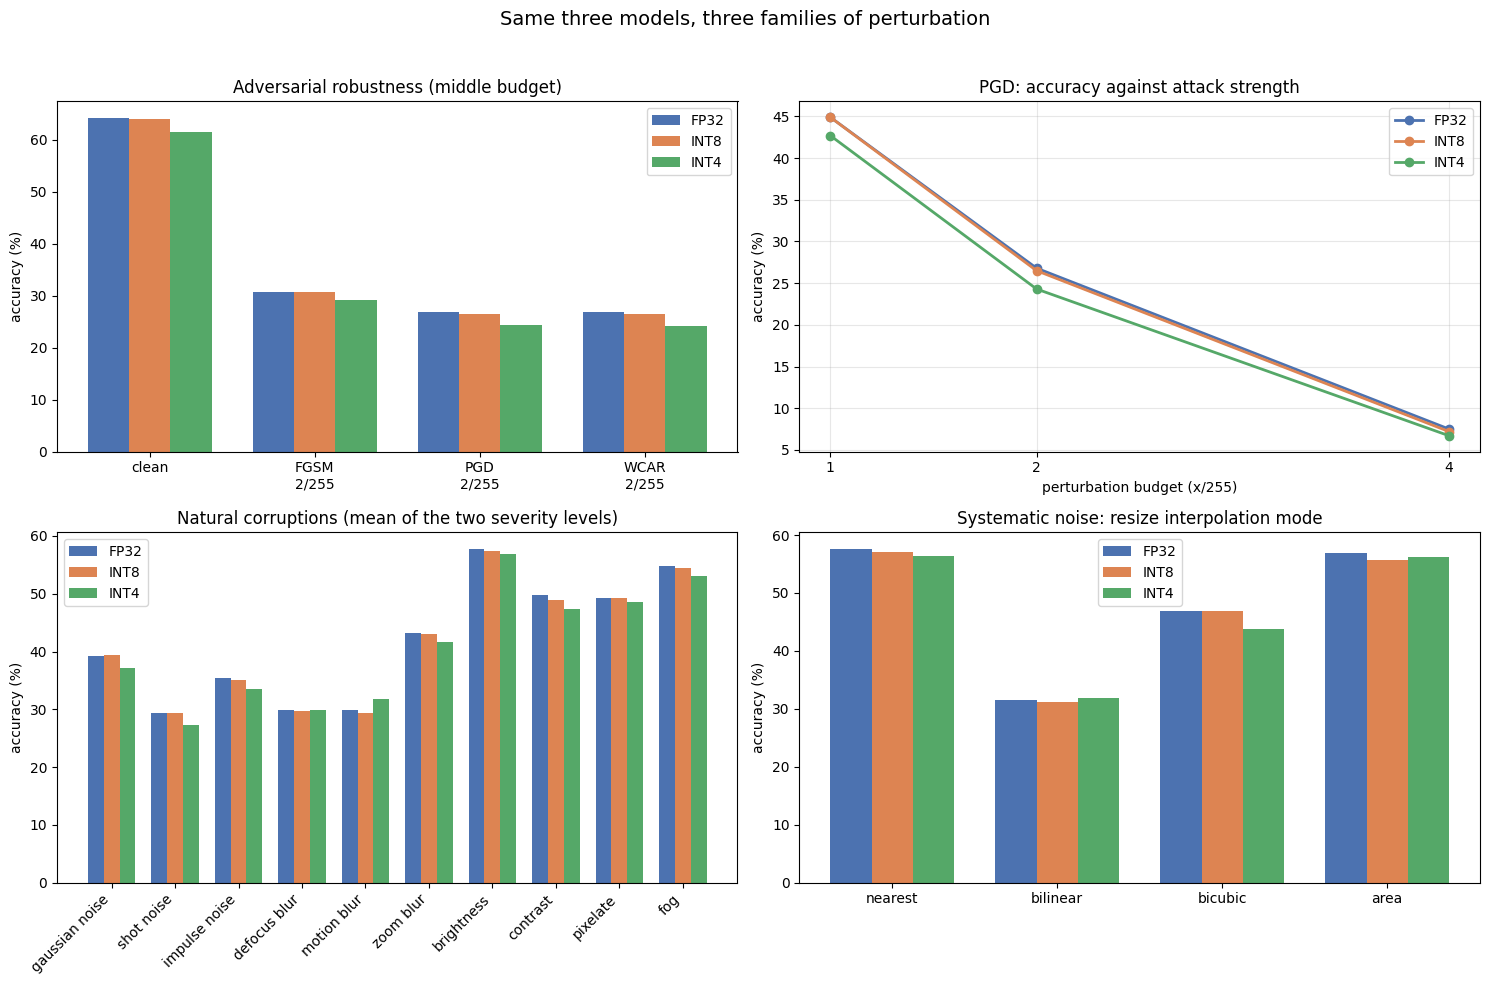

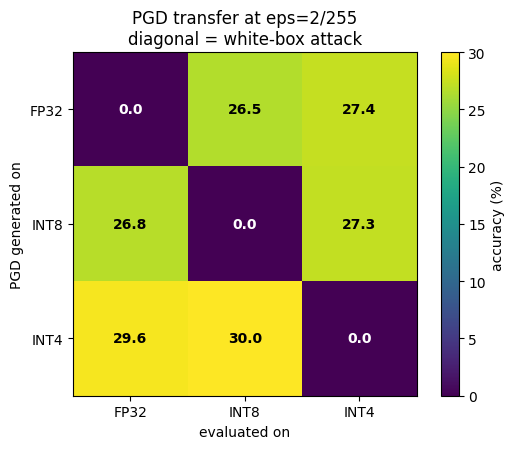

In [8]:
# ---------------- Plots ----------------
COLORS = {"FP32": "#4C72B0", "INT8": "#DD8452", "INT4": "#55A868"}
WIDTH = 0.25

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (1) adversarial robustness at the middle budget
ax = axes[0, 0]
bar_labels = ["clean", "FGSM\n2/255", "PGD\n2/255", "WCAR\n2/255"]
positions = np.arange(len(bar_labels))
for i, model_name in enumerate(MODEL_NAMES):
    values = [accuracy_of(model_name, "clean"),
              accuracy_of(model_name, "FGSM eps=2/255"),
              accuracy_of(model_name, "PGD eps=2/255"),
              wcar(model_name, "2/255")]
    ax.bar(positions + (i - 1) * WIDTH, values, WIDTH, label=model_name, color=COLORS[model_name])
ax.set_xticks(positions)
ax.set_xticklabels(bar_labels)
ax.set_ylabel("accuracy (%)")
ax.set_title("Adversarial robustness (middle budget)")
ax.legend()

# (2) accuracy against perturbation budget
ax = axes[0, 1]
budgets = [1, 2, 4]
for model_name in MODEL_NAMES:
    values = [accuracy_of(model_name, f"PGD eps={label}") for label, _ in EPS_LIST]
    ax.plot(budgets, values, marker="o", linewidth=2, label=model_name, color=COLORS[model_name])
ax.set_xlabel("perturbation budget (x/255)")
ax.set_ylabel("accuracy (%)")
ax.set_title("PGD: accuracy against attack strength")
ax.set_xticks(budgets)
ax.grid(alpha=0.3)
ax.legend()

# (3) natural corruptions
ax = axes[1, 0]
names = list(CORRUPTIONS)
positions = np.arange(len(names))
for i, model_name in enumerate(MODEL_NAMES):
    values = [np.mean([accuracy_of(model_name, f"{name} L{level}") for level in (1, 2)]) for name in names]
    ax.bar(positions + (i - 1) * WIDTH, values, WIDTH, label=model_name, color=COLORS[model_name])
ax.set_xticks(positions)
ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_ylabel("accuracy (%)")
ax.set_title("Natural corruptions (mean of the two severity levels)")
ax.legend()

# (4) systematic noise: resize interpolation
ax = axes[1, 1]
positions = np.arange(len(RESIZE_MODES))
for i, model_name in enumerate(MODEL_NAMES):
    values = [accuracy_of(model_name, f"resize {mode}") for mode in RESIZE_MODES]
    ax.bar(positions + (i - 1) * WIDTH, values, WIDTH, label=model_name, color=COLORS[model_name])
ax.set_xticks(positions)
ax.set_xticklabels(RESIZE_MODES)
ax.set_ylabel("accuracy (%)")
ax.set_title("Systematic noise: resize interpolation mode")
ax.legend()

fig.suptitle("Same three models, three families of perturbation", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# (5) transfer matrix heatmap
matrix = np.array([[transfer_pgd[attacker][victim].float().mean().item() * 100 for victim in MODEL_NAMES]
                   for attacker in MODEL_NAMES])
fig, ax = plt.subplots(figsize=(5.8, 4.6))
image = ax.imshow(matrix, cmap="viridis", vmin=0, vmax=max(matrix.max(), 1))
ax.set_xticks(range(len(MODEL_NAMES)))
ax.set_xticklabels(MODEL_NAMES)
ax.set_yticks(range(len(MODEL_NAMES)))
ax.set_yticklabels(MODEL_NAMES)
ax.set_xlabel("evaluated on")
ax.set_ylabel("PGD generated on")
for i in range(len(MODEL_NAMES)):
    for j in range(len(MODEL_NAMES)):
        ax.text(j, i, f"{matrix[i, j]:.1f}", ha="center", va="center", fontweight="bold",
                color="white" if matrix[i, j] < matrix.max() / 2 else "black")
ax.set_title("PGD transfer at eps=2/255\ndiagonal = white-box attack")
fig.colorbar(image, ax=ax, label="accuracy (%)")
fig.tight_layout()
plt.show()


## How to read these results

Start with the summary table. Four questions it answers:

1. **Does quantization change adversarial robustness?** Compare `PGD 2/255` and `WCAR 2/255` across the three columns. RobustMQ reported quantized models *beating* their float counterpart here, and that lower bits were *more* robust. Look at the printed ranking lines at the bottom of the previous cell: they tell you directly whether our models reproduce that ordering.
2. **Does it change natural robustness?** Compare `mNR` and `NCI`. RobustMQ reported quantized models doing *worse* than float here, and worse as the bit-width drops. Again the printed ranking checks it.
3. **Is the pattern different per noise family?** That is the paper's central claim: quantization trades adversarial robustness for natural robustness. Read the adversarial panel and the corruption panel side by side.
4. **Do attacks transfer between precisions?** The heatmap shows what happens when a PGD attack made on one model is applied to another. A large off-diagonal gap means the perturbations do not transfer well across precisions -- which is exactly the effect that makes an ensemble of differently-quantized models a plausible defence.

## Caveats to state before anyone else does

- **This is not a reproduction of RobustMQ.** They used ImageNet, four architectures, four bit-widths and QAT (DoReFa/PACT/LSQ). We use CIFAR-10, one small CNN, 8 and 4 bits, and post-training quantization. Our numbers are the same *shape* of experiment on a much smaller scale.
- **The adversarial gain in the paper is a QAT effect.** Their quantized models were trained *with* the rounding in the loop, so the network adapted to it -- that is where the robustness came from. Our models never adapted, so expect much smaller, possibly absent, differences. If INT4 does not beat FP32 here, that is a legitimate and explainable finding, not a broken experiment.
- **The INT8 attacks are approximate.** Int8 kernels are not differentiable, so the attack was generated on a float twin carrying the dequantized int8 weights. The twin matches the real model on most images, but not all, so INT8's robustness is reported slightly *optimistically*. INT4 and FP32 are attacked exactly.
- **1,000 images is a small sample.** The standard error on an accuracy near 80% is about 1.3 pp, so differences below roughly 3 pp should not be read as real without more data. Raise `ROBUST_N` to 5,000 if you want tighter numbers.
- **Our corruption set is 10 of the paper's 15**, implemented directly in torch rather than with the official ImageNet-C code, and `fog` is an approximation. The ordering of which corruption hurts most is more trustworthy than the exact values.
- **Systematic noise here is resize modes only.** The paper also varied image decoders (Pillow/OpenCV/FFmpeg), which cannot be reproduced inside a tensor pipeline.

## Next steps that would strengthen it

- Raise `ROBUST_N` to 5,000 and add a third severity level for the corruptions.
- Run the same file with a deeper architecture (`torchvision.models.resnet18`) -- the paper found depth and capacity matter as much as bit-width.
- Add a 2-bit row with the packed int4 code (the precision sweep in the accuracy notebook shows how), since the paper's strongest effects appear at 2 bits.
- Swap PTQ for quantization-aware training so the models can adapt to rounding, which is the condition under which the paper's adversarial finding appears.
